# CSAI3121 - Machine Learning and Intelligent Data Analysis
# Lab 8: KMeans and DBSCAN 
## Full mark: 30 marks

60 minutes | Student name: Liao Tian | ID: P2421086

Goal: learn KMeans, DBSCAN, and parameter selection on a simple generated dataset.

By the end of this lab you should be able to:
1. Fit KMeans and inspect labels, centroids, inertia, and silhouette score.
2. Compare KMeans values from k=2 through k=10.
3. Fit DBSCAN and explain eps, min_samples, and noise label -1.
4. Use a k-distance graph to choose DBSCAN eps, then inspect clusters and noise.

You will complete a data plot, a KMeans k=2 plot, a silhouette plot for k=2 through k=10, a k-distance graph, a DBSCAN plot, and the quiz.


## 1. Create and inspect the data 
Run the setup cell. 

X shape: (300, 2)
Hidden labels are not used for clustering or parameter selection.


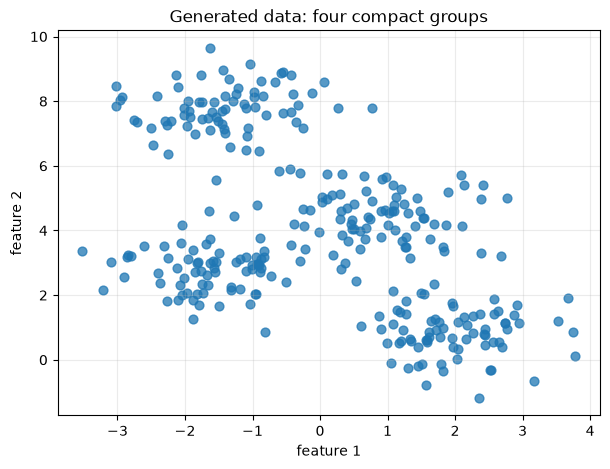

In [425]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

RANDOM_STATE = 0
N_SAMPLES = 300
X, y_hidden = make_blobs(n_samples=N_SAMPLES, centers=4, cluster_std=0.75, random_state=RANDOM_STATE)
print("X shape:", X.shape)
print("Hidden labels are not used for clustering or parameter selection.")
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], s=40, alpha=0.75)
plt.xlabel("feature 1"); plt.ylabel("feature 2")
plt.title("Generated data: four compact groups")
plt.grid(alpha=0.25); plt.show()

### Q1: How many "broad" groups can you see? (2 marks) 
Your answer: 4.

## 2. Fit KMeans with k=2
Colour the points by predicted cluster, show the centroids with a large red marker, and calculate the silhouette score.

Hints:
- Use `means = KMeans(n_clusters=2, random_state=42, n_init=10)`.
- `n_clusters` is the number of centroids.
- `random_state=42` makes the random starting process reproducible.
- `n_init=10` tries several starting centroid positions and keeps the best result.
- `kmeans_labels = fit_predict(X)` fits and returns one label per point.
- `kmeans.cluster_centers_` contains centroid coordinates.
- Use `silhouette_score(X, kmeans_labels)`. Larger is usually better. Use `round(..., 3) to round values to 3 decimal places.
- Cluster labels are arbitrary names.

Centroids:
 [[ 0.43595616  2.62374242]
 [-1.26733756  7.58247986]]

Silhouette Score: 0.506


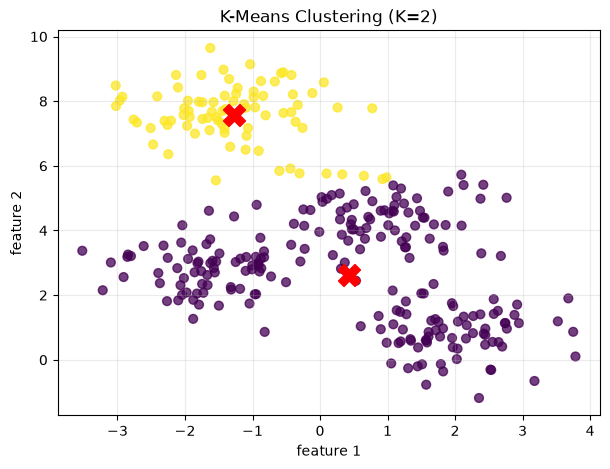

In [426]:
# TODO: fit the model and save labels
# TODO: print centroids and silhouette score
# TODO: plot points coloured by labels and plot centroids with marker="X" 

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X)

centroids = kmeans.cluster_centers_
print("Centroids:\n", centroids)

score = silhouette_score(X, kmeans_labels)
print("\nSilhouette Score:", round(score, 3))

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap='viridis', s=40, alpha=0.75)
plt.scatter(centroids[:,0],centroids[:,1],c='red',marker='X',s=250)
plt.xlabel("feature 1"); plt.ylabel("feature 2")
plt.title("K-Means Clustering (K=2)")
plt.grid(alpha=0.25); plt.show()

### Q2: 
Record silhouette score: 0.506. 

Does k=2 match the groups in the first plot? No. (2 marks)

## 3. Compare k=2 through k=10 
Fit one KMeans model for each k from 2 through 10. Store silhouette scores and plot k against the score. Choose the best k and plot its clustering.

Hints:
- Use `k_values = range(2, 11)`.
- Create empty lists before the loop.
- Inside the loop, create a new model, call `fit_predict`, and append `silhouette_score(X, kmeans_labels)`.
- Use `plt.plot(k_values, silhouettes, marker="o")`.
- The best candidate has the largest score. 


,k,silhouette
0,2,0.506467
1,3,0.531304
2,4,0.603151
3,5,0.517838
4,6,0.452303
5,7,0.383860
6,8,0.330520
7,9,0.344329
8,10,0.351050


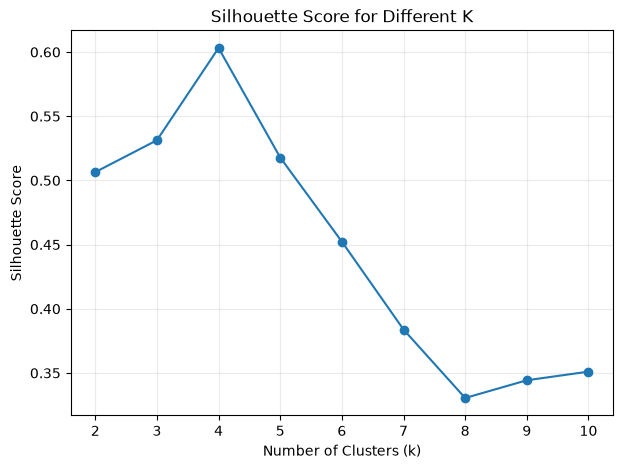

Best k: 4


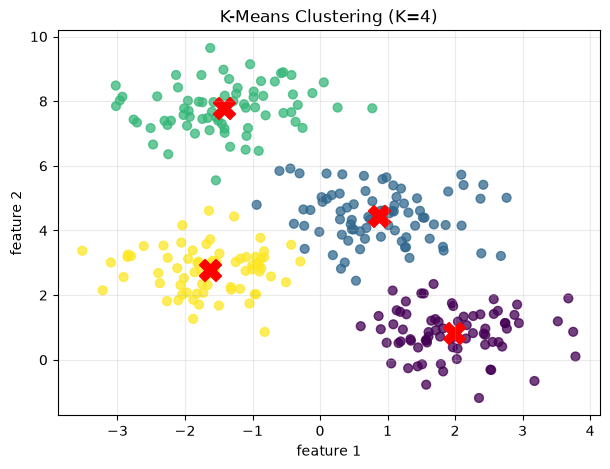

In [427]:
k_values = range(2, 11)
silhouettes = []

# TODO: loop through k_values, fit KMeans, and append silhouette
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_labels = kmeans.fit_predict(X)

    silhouettes.append(silhouette_score(X, kmeans_labels))

# TODO: make a results DataFrame and plot k against silhouette score
results = pd.DataFrame({
    'k': list(k_values),
    'silhouette': silhouettes
})

display(results)

plt.figure(figsize=(7,5))
plt.plot(k_values, silhouettes, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K")
plt.grid(alpha=0.25)
plt.show()


# TODO: find k_best, fit a final model, and plot labels and centroids
k_best = list(k_values)[np.argmax(silhouettes)]
print("Best k:", k_best)

best_kmeans = KMeans(n_clusters=k_best, random_state=42, n_init=10)
best_labels = best_kmeans.fit_predict(X)
best_centroids = best_kmeans.cluster_centers_



plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=best_labels, s=40, alpha=0.75)
plt.scatter(best_centroids[:, 0], best_centroids[:, 1], c='red', marker='X', s=250)

plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title(f"K-Means Clustering (K={k_best})")
plt.grid(alpha=0.25)
plt.show()

### Q3: 

Chosen k: 4  

Reason: k=4 has the highest silouette score, means it has better cluster separation. (3 marks)

## 4. Use a k-distance graph to choose DBSCAN eps 
DBSCAN needs values for `min_samples` and `eps`:

- `min_samples` specifies how many points must be inside a neighbourhood for a point to be considered a **core point**. DBSCAN includes the point itself in this count.
- `eps` specifies the radius of that neighbourhood.

For this two-feature dataset, we will use `min_samples=8`. This is a moderately strict density requirement. We will then use a **k-distance graph** to estimate a suitable starting value for `eps`.


Why link `n_neighbors` to `min_samples`?

If `min_samples=8`, DBSCAN asks whether a point has an eight-point neighbourhood, including the point itself, within the radius `eps`.

To estimate the radius needed for this neighbourhood:

1. Find the eight-neighbour distance list for every point.
2. Take the final distance in each list. This is the radius needed for that point to have an eight-point neighbourhood.
3. Sort these distances from smallest to largest.
4. Plot the sorted distances.
5. Look for the **elbow** or **knee**, where the distances begin to increase more sharply.

Most points inside dense regions have relatively small k-distances. Boundary or isolated points need a larger radius to reach enough neighbours, so their k-distances appear in the rising part of the graph.

The elbow provides a reasonable **starting value** for `eps`. It does not guarantee the best clustering, so values near the elbow should still be tested and compared visually.

Implementation hints:

- Create the neighbour-search model with: `neighbors = NearestNeighbors(n_neighbors=min_samples)`
- Prepare it using: `neighbors.fit(X)`
- Obtain the neighbour distances using: `distances, indices = neighbors.kneighbors(X)`
- The last column contains the final distance in each point’s eight-neighbour distance list: `k_distances = distances[:, -1]`
- Sort the distances:`k_distances_sorted = np.sort(k_distances)`
- Plot the sorted values:`plt.plot(k_distances_sorted)`

Observe the plot:
- Look for the region where the curve starts to rise more sharply. For this dataset, the visible elbow is approximately around `0.7`.
- Treat this as a starting point. In the next task, compare `eps=0.6` and `eps=0.7`. You may find that `0.7` merges two groups, while `0.6` preserves the four visible groups.

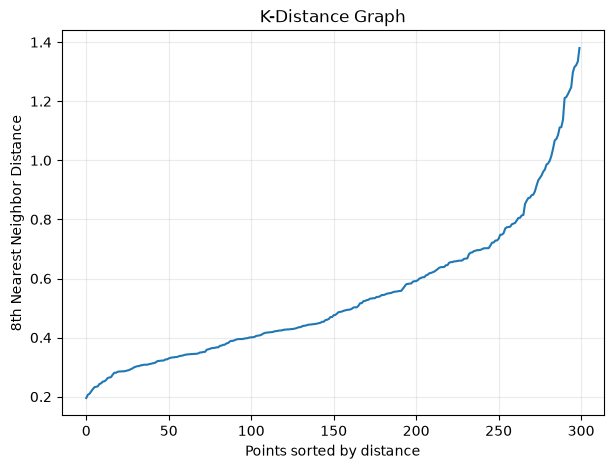

In [428]:
min_samples = 8
neighbors = NearestNeighbors(n_neighbors=min_samples)

# TODO: fit neighbors on X and call kneighbors(X)
neighbors.fit(X)

# distances: 每个数据点到 8 个最近邻居的距离        
# indices：这 8 个邻居在原始数据中的索引
distances, indices = neighbors.kneighbors(X)


# TODO: distances now store for each point, the distance to the 1st, 2nd, ... kth, nearest neighbors
k_distances = distances[:,-1]
# print(k_distances)
# TODO: retrieve the kth nearest neighbor distances and sort in increasing order
k_distances_sorted = np.sort(k_distances)

# TODO: plot the sorted k-distances against point order
# TODO: estimate eps from the elbow

plt.figure(figsize=(7, 5))
plt.plot(k_distances_sorted)
plt.xlabel("Points sorted by distance")
plt.ylabel("8th Nearest Neighbor Distance")
plt.title("K-Distance Graph")
plt.grid(alpha=0.25)
plt.show()

### Q4: 

Estimated eps from the elbow: 0.7. 

Why are the last few points much higher than most of the curve? 

Because these points are not in dense area. They need large radius to find 8 neighbouring points. (3 marks)

## 5. Fit DBSCAN and check nearby eps values
Use `min_samples=8` and start with `eps=0.60`, a value close to the elbow. Count number of clusters, number of noise points, fraction of noise points, then plot the result.

Plot requirements:
- Plot each non-noise cluster points (`db_label != -1`), use a different colour for different clusters
- Plot noise points (`db_label == -1`) as black `x` markers.
- Put in the plot title "eps = 0.6 | number_of_clusters | fraction_of_noise_points"



Number of clusters: 4
Number of noise points: 38
Fraction of noise points: 0.127


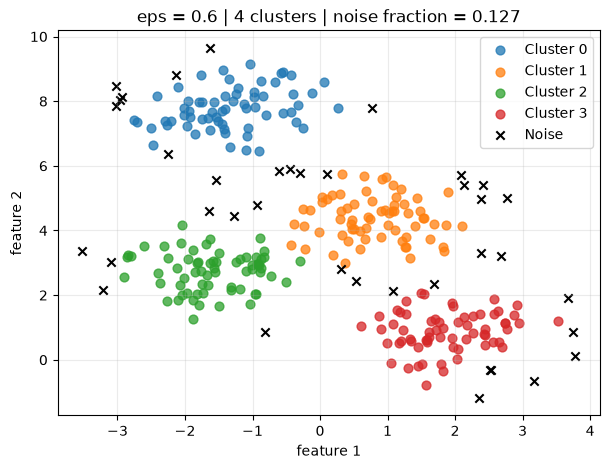

In [429]:
eps_chosen = 0.60
dbscan = DBSCAN(eps=eps_chosen, min_samples=min_samples)

# TODO: db_labels = dbscan.fit_predict(X)  
db_labels = dbscan.fit_predict(X)

# TODO: count number of clusters by len(set(db_labels) - {-1}
num_clusters = len(set(db_labels) - {-1})
print("Number of clusters:", num_clusters)

# TODO: count number of noise points by int((db_labels == -1).sum()
num_noise_points = int((db_labels == -1).sum())
print("Number of noise points:", num_noise_points)

# TODO: compute fraction of noise points by round(num_noise_points/N_SAMPLES,3)
noise_fraction = round(num_noise_points / N_SAMPLES, 3)
print("Fraction of noise points:", noise_fraction)

# TODO: plot clustered points with cluster color, marker='o', label='Clustered'
#       plot noise points separately with color='black', marker='x', label='Noise'
#       display title with the eps value, number of clusters, and fraction of noise point.
plt.figure(figsize=(7, 5))

for label in set(db_labels) - {-1}:
    # X[db_labels == 0, 0] 从 X 中取出属于 Cluster 0 的所有数据点的第 0 列
    # X[db_labels == 0, 1] 从 X 中取出属于 Cluster 0 的所有数据点的第 1 列
    plt.scatter(X[db_labels == label, 0], X[db_labels == label, 1], s=40, alpha=0.75, label=f"Cluster {label}")

plt.scatter(X[db_labels == -1, 0], X[db_labels == -1, 1], c='black', marker='x', label='Noise')

plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title(f"eps = {eps_chosen} | {num_clusters} clusters | noise fraction = {noise_fraction}")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

Plot and inspect how `eps` values affect the clustering results:
- Compare `eps` values from `0.1` through `1.0` in steps of `0.1`, while keeping `min_samples=8`
- Make a `2 x 5` panel of plots and record only the number of clusters and number/fraction of noise points. 
- Smaller `eps` usually creates more noise or separates groups into extra clusters.
- Larger `eps` usually reduces noise, but can join nearby clusters.
- Use `eps_values = np.arange(0.1, 1.1, 0.1)`.
- Use `fig, axes = plt.subplots(2, 5, figsize=(15,8))` and loop over `axes.flat` by enumerate.


eps=0.1, clusters=0, noise_points=300, noise_fraction=1.0
eps=0.2, clusters=1, noise_points=292, noise_fraction=0.973
eps=0.3, clusters=5, noise_points=237, noise_fraction=0.79
eps=0.4, clusters=5, noise_points=127, noise_fraction=0.423
eps=0.5, clusters=4, noise_points=74, noise_fraction=0.247
eps=0.6, clusters=4, noise_points=38, noise_fraction=0.127
eps=0.7, clusters=3, noise_points=21, noise_fraction=0.07
eps=0.8, clusters=3, noise_points=8, noise_fraction=0.027
eps=0.9, clusters=2, noise_points=3, noise_fraction=0.01
eps=1.0, clusters=1, noise_points=1, noise_fraction=0.003


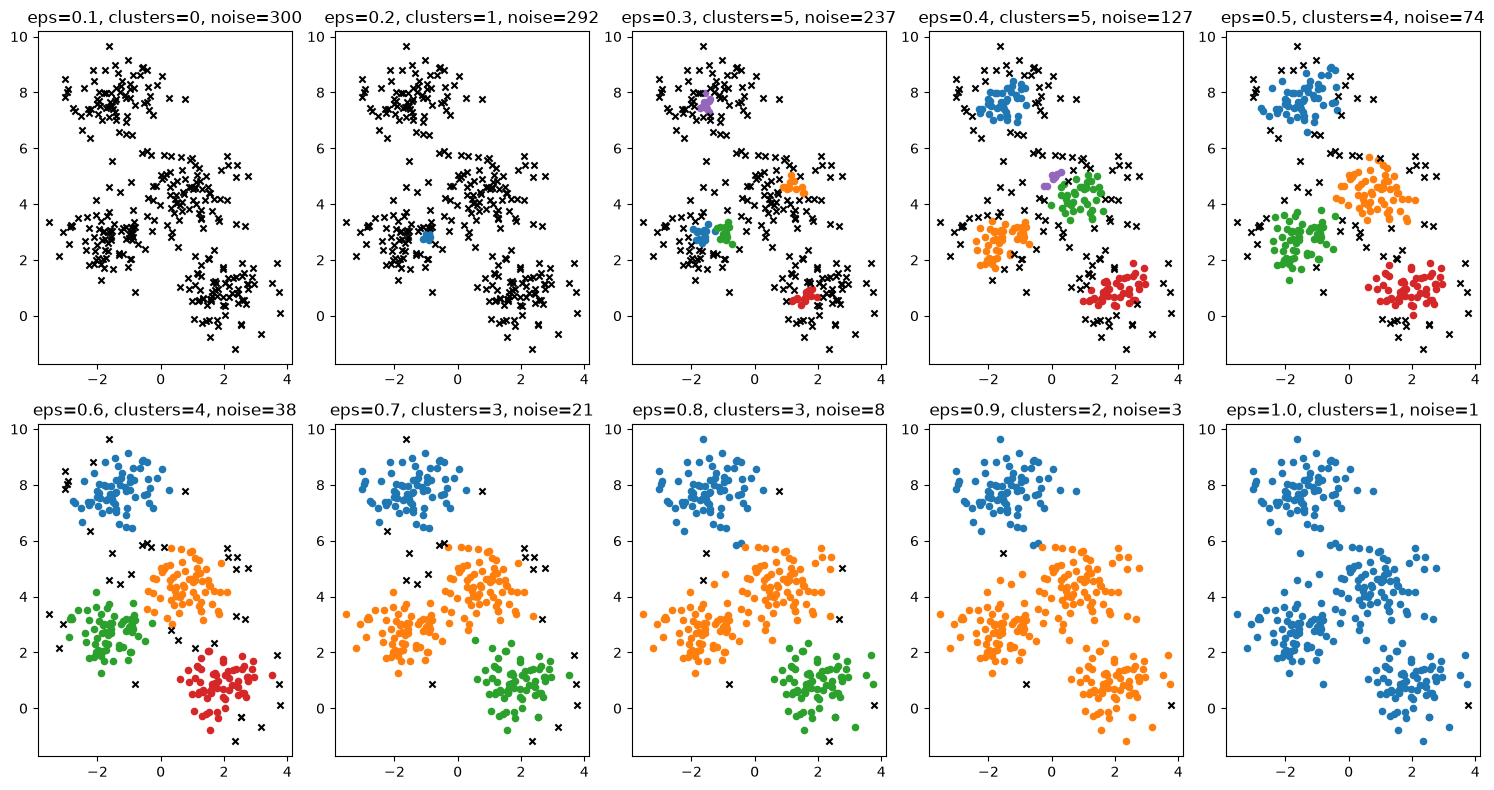

In [430]:
eps_values = np.arange(0.1, 1.1, 0.1)

# TODO: create a 2 x 5 figure
fig, axes = plt.subplots(2, 5, figsize=(15,8))

# TODO: for each eps and subplot, fit DBSCAN and plot clusters/noise
# TODO: record clusters, noise_points, and noise_fraction
# TODO: decide whether to keep eps=0.60


for i, eps in enumerate(eps_values):
    dbscan = DBSCAN(eps=eps, min_samples = 8)
    labels = dbscan.fit_predict(X)

    num_clusters = len(set(labels)-{-1})
    num_noise = (labels == -1).sum()
    noise_fraction = round(num_noise / N_SAMPLES, 3)

    print(f"eps={eps:.1f}, clusters={num_clusters}, "
          f"noise_points={num_noise}, noise_fraction={noise_fraction}")
    

    ax = axes.flat[i]
    for label in set(labels) - {-1}:
        ax.scatter(X[labels==label, 0], X[labels==label, 1], s=20)

    ax.scatter(X[labels==-1, 0], X[labels==-1,1], c='black', marker='x', s=20)
    ax.set_title(f"eps={eps:.1f}, clusters={num_clusters}, noise={num_noise}")


plt.tight_layout()
plt.show()



### Q5: Observe the plots, describe what happens at very small eps values, near the elbow, and at very large eps values. Which eps is a good choice? Explain your decision. 

Chosen eps: 0.6  

Why: 
When eps is small, most points are classified as noise because the neighbourhood is too small to find enough neighbours.
When eps is too large, nearby clusters get together. For example, eps=0.7 only has three clusters, eps=1.0 only has one cluster.
So, eps=0.6 is good because it separates the four groups, and the noise point is low.(10 marks)


## 6. Compare the methods and answer questions


### Q6: Check your understanding (10 marks)
   
1. In KMeans, what does n_clusters specify?
- A. Number of features
- B. Number of clusters/centroids
- C. Number of plots
- D. Number of noise points

2. Why set random_state=42 for KMeans?
- A. Scale data
- B. Make random starting reproducible
- C. Choose k automatically
- D. Remove noise

3. What does a larger silhouette score usually indicate?
- A. Better-separated clusters
- B. More missing values  
- C. More noise  
- D. Larger dataset

4. What does fit_predict(X) return when used with KMeans?
- A. The coordinates of the centroids
- B. The inertia for each point
- C. A predicted cluster label for every point  
- D. The silhouette score

5. What does DBSCAN label -1 mean?
- A. First cluster
- B. Centroid  
- C. Noise  
- D. Validation fold

6. What does DBSCAN eps control?
- A. Neighbourhood radius
- B. Number of centroids
- C. Number of features
- D. Number of plots

7. What does min_samples control?
- A. Density requirement for a core point
- B. Maximum k
- C. KMeans restarts
- D. Silhouette range

8. What is plotted on the vertical axis of the k-distance graph used here?
- A. Sorted distance to the k-th nearest neighbour
- B. KMeans inertia
- C. Cluster label
- D. Hidden class label

9. Which part of the k-distance graph suggests a starting value for eps?
- A. The first point
- B. The elbow where distances begin rising sharply
- C. The plot title
- D. The horizontal-axis maximum

10. What generally happens when DBSCAN’s eps is too large?
- A. Nearby clusters may become connected and merge
- B. Every point becomes noise
- C. min_samples automatically decreases
- D. The k-distance graph disappears

Enter answers below as letters A-D.

In [431]:
answers = ['B', 'B', 'A', 'C', 'C', 'A', 'A', 'A', 'B', 'A']
assert len(answers) == 10
print('Answers recorded:', answers)



Answers recorded: ['B', 'B', 'A', 'C', 'C', 'A', 'A', 'A', 'B', 'A']
